# Figure 7A/B reproduction: β-VAE (Higgins et al., 2017)

**Run in Google Colab with a GPU.** This notebook trains two independent models (β=1 and β=4) and derives all plots from model inference. It does **not** include pretrained weights or fabricated results.

**Paper-specified:** binary 64×64 images, 737,280 Cartesian-product samples, FC encoder 1200→1200, 10 Gaussian latents, FC decoder 1200→1200→1200→4096, Adagrad 0.01, β ∈ {1,4}, Gaussian prior, Bernoulli likelihood, −3…3 latent traversals. See Section 4.2, Fig. 7 and Appendix Table 1.

**Implementation decisions not specified in the paper:** epochs/steps, batch size, exact initialization, data ordering, checkpoint selection, use of logits for Bernoulli output, posterior variance estimation method, reference images, latent-response normalization and plot layout. We apply Tanh to decoder hidden layers and leave output as Bernoulli logits; this resolves the ambiguous 'Tanh activation. Bernoulli' table entry. We report both posterior variance and per-coordinate KL; columns sorted by mean posterior variance (ascending). The paper's exact sorting direction is not explicit.

**Compute note:** full factorial evaluation is expensive. The response plots use seeded, stratified subsamples by default. Set `RESPONSE_PER_LEVEL` higher or `EXACT_RESPONSES=True` for exhaustive marginalization. The default training is a computational reduction, not a claim to match the authors' training duration.


In [9]:
import os, random, json, time
from pathlib import Path
import numpy as np, torch, torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
SEED=2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
OUT=Path('/content/beta_vae_fig7_results' if Path('/content').exists() else './beta_vae_fig7_results'); OUT.mkdir(parents=True,exist_ok=True)
BATCH_SIZE = 128
EPOCHS = 10
MAX_STEPS_PER_EPOCH = None
NUM_WORKERS=2; RESPONSE_PER_LEVEL=512; EXACT_RESPONSES=False
print('Device:',DEVICE,'Results:',OUT)


Device: cuda Results: /content/beta_vae_fig7_results


## Dataset acquisition

Upload the **original dSprites NPZ** to Colab (or mount Drive). This notebook intentionally does not search for code or repositories. Set `DATA_PATH` to the NPZ file. Standard dSprites archives include `imgs` and `latents_classes`. The factor order is [color, shape, scale, orientation, posX, posY]. Color is constant. We verify the factorial cardinalities before training.


In [10]:
DATA_PATH='/content/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz'
if not Path(DATA_PATH).exists():
    from google.colab import files
    print('Upload the original dSprites .npz dataset')
    uploaded=files.upload(); DATA_PATH=next(iter(uploaded))
raw=np.load(DATA_PATH,allow_pickle=True,encoding='latin1')
imgs=raw['imgs']; factors=raw['latents_classes']
assert imgs.shape==(737280,64,64),imgs.shape
assert factors.shape[0]==737280
assert [len(np.unique(factors[:,i])) for i in range(6)]==[1,3,6,40,32,32]
print('Dataset validated:',imgs.shape, factors.shape)
class SpriteDataset(Dataset):
    def __len__(self):return len(imgs)
    def __getitem__(self,i):return torch.from_numpy(np.array(imgs[i],dtype=np.float32)).view(-1)
loader=DataLoader(SpriteDataset(),batch_size=BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS,pin_memory=(DEVICE=='cuda'))


Dataset validated: (737280, 64, 64) (737280, 6)


## Network and exact loss

The reconstruction term is a pixelwise **sum**, averaged across the minibatch. This matters: averaging across all 4096 pixels would change the effective strength of β by a factor of 4096. We use the reparameterization trick only during training; inference plots use posterior means.


In [11]:
class BetaVAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder=nn.Sequential(nn.Linear(4096,1200),nn.ReLU(),nn.Linear(1200,1200),nn.ReLU())
        self.mu=nn.Linear(1200,10);self.logvar=nn.Linear(1200,10)
        self.decoder=nn.Sequential(nn.Linear(10,1200),nn.Tanh(),nn.Linear(1200,1200),nn.Tanh(),nn.Linear(1200,1200),nn.Tanh(),nn.Linear(1200,4096))
    def encode(self,x):
        h=self.encoder(x);return self.mu(h),self.logvar(h)
    def decode(self,z):return self.decoder(z)
    def forward(self,x):
        mu,lv=self.encode(x);z=mu+torch.randn_like(mu)*torch.exp(0.5*lv)
        return self.decode(z),mu,lv

def loss_parts(logits,x,mu,lv,beta):
    recon=F.binary_cross_entropy_with_logits(logits,x,reduction='none').sum(1).mean()
    kl=(-0.5*(1+lv-mu.square()-lv.exp()).sum(1)).mean()
    return recon+beta*kl,recon,kl

def train(beta):
    torch.manual_seed(SEED) # matched initial weights across beta conditions
    model=BetaVAE().to(DEVICE);optim=torch.optim.Adagrad(model.parameters(),lr=1e-2)
    history=[];step=0
    for epoch in range(EPOCHS):
        model.train(); sums=np.zeros(3);count=0;t0=time.time()
        for i,x in enumerate(loader):
            if MAX_STEPS_PER_EPOCH is not None and i>=MAX_STEPS_PER_EPOCH:break
            x=x.to(DEVICE,non_blocking=True);optim.zero_grad(set_to_none=True)
            logits,mu,lv=model(x);loss,recon,kl=loss_parts(logits,x,mu,lv,beta)
            if not torch.isfinite(loss):raise RuntimeError('Nonfinite loss')
            loss.backward();optim.step()
            sums+=np.array([loss.item(),recon.item(),kl.item()])*len(x);count+=len(x);step+=1
        values=(sums/count).tolist();history.append({'epoch':epoch+1,'loss':values[0],'recon':values[1],'kl':values[2],'steps':step})
        print(f'beta={beta} epoch={epoch+1}/{EPOCHS} loss={values[0]:.2f} recon={values[1]:.2f} kl={values[2]:.2f} sec={time.time()-t0:.1f}')
        torch.save({'model':model.state_dict(),'beta':beta,'epoch':epoch+1,'history':history,'seed':SEED},OUT/f'beta{beta}.pt')
        (OUT/f'beta{beta}_history.json').write_text(json.dumps(history,indent=2))
    return model,history
models={};histories={}
for beta in [1,4]:models[beta],histories[beta]=train(beta)


beta=1 epoch=1/10 loss=141.37 recon=123.41 kl=17.96 sec=46.9
beta=1 epoch=2/10 loss=102.89 recon=88.28 kl=14.61 sec=47.4
beta=1 epoch=3/10 loss=92.58 recon=77.36 kl=15.22 sec=47.2
beta=1 epoch=4/10 loss=89.10 recon=73.59 kl=15.51 sec=47.1
beta=1 epoch=5/10 loss=86.04 recon=69.95 kl=16.09 sec=47.1
beta=1 epoch=6/10 loss=83.39 recon=66.93 kl=16.45 sec=46.8
beta=1 epoch=7/10 loss=80.98 recon=64.24 kl=16.74 sec=47.1
beta=1 epoch=8/10 loss=79.14 recon=62.22 kl=16.92 sec=47.1
beta=1 epoch=9/10 loss=77.70 recon=60.66 kl=17.03 sec=47.0
beta=1 epoch=10/10 loss=76.38 recon=59.25 kl=17.13 sec=48.1
beta=4 epoch=1/10 loss=167.66 recon=122.21 kl=11.36 sec=47.4
beta=4 epoch=2/10 loss=136.20 recon=97.12 kl=9.77 sec=47.4
beta=4 epoch=3/10 loss=134.59 recon=95.34 kl=9.81 sec=47.2
beta=4 epoch=4/10 loss=133.75 recon=94.42 kl=9.83 sec=46.7
beta=4 epoch=5/10 loss=133.16 recon=93.79 kl=9.84 sec=46.9
beta=4 epoch=6/10 loss=132.68 recon=93.28 kl=9.85 sec=46.7
beta=4 epoch=7/10 loss=132.22 recon=92.80 kl=9.85 

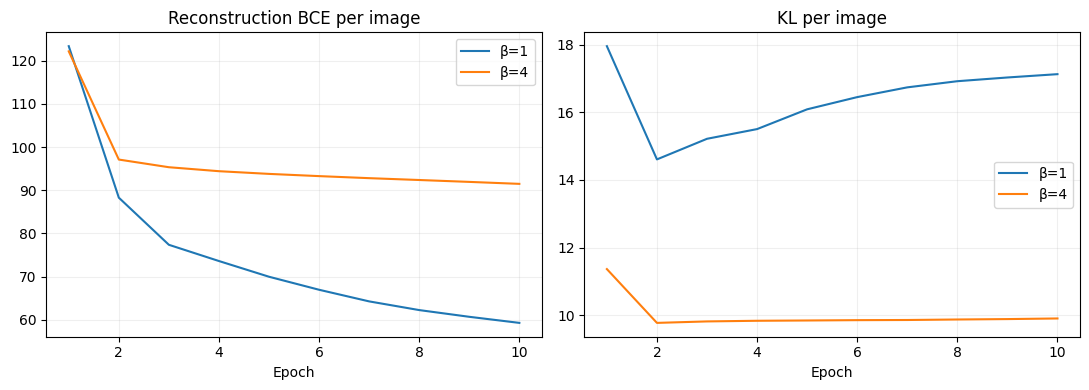

In [12]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
for beta,h in histories.items():
    axs[0].plot([v['epoch'] for v in h],[v['recon'] for v in h],label=f'β={beta}')
    axs[1].plot([v['epoch'] for v in h],[v['kl'] for v in h],label=f'β={beta}')
for ax,title in zip(axs,['Reconstruction BCE per image','KL per image']):ax.set(title=title,xlabel='Epoch');ax.legend();ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(OUT/'training_diagnostics.png',dpi=180);plt.show()


## Figure 7 responses

Compute posterior means on seeded conditional samples for each factor value. Position heatmaps average over shapes, rotations and scales. Scale and rotation curves average over the remaining factors, with separate curves for the three shapes. Factor labels are **never used in training**.


In [13]:
@torch.no_grad()
def infer_indices(model,indices,batch=512):
    model.eval();parts=[]
    for start in range(0,len(indices),batch):
        x=torch.from_numpy(np.asarray(imgs[indices[start:start+batch]],dtype=np.float32).reshape(-1,4096)).to(DEVICE)
        mu,_=model.encode(x);parts.append(mu.cpu().numpy())
    return np.concatenate(parts,axis=0)

rng=np.random.default_rng(SEED+19)
# dSprites indexing: shape,scale,orientation,x,y; color constant
sizes=np.array([3,6,40,32,32]);strides=np.array([6*40*32*32,40*32*32,32*32,32,1])
def indices_from_factor_matrix(mat):return (mat*strides).sum(1).astype(np.int64)
def conditional_indices(axis,value,n):
    # Other factors are sampled independently and uniformly.
    mat=np.column_stack([rng.integers(0,s,size=n) for s in sizes]);mat[:,axis]=value
    return indices_from_factor_matrix(mat)

def responses(model):
    # Global variance and KL use an independent seeded random sample.
    sample=rng.choice(len(imgs),size=min(20000,len(imgs)),replace=False)
    mu=infer_indices(model,sample)
    # posterior variance means E_x[var(z|x)], not variance of posterior means
    lvparts=[];model.eval()
    with torch.no_grad():
        for start in range(0,len(sample),512):
            x=torch.from_numpy(np.asarray(imgs[sample[start:start+512]],dtype=np.float32).reshape(-1,4096)).to(DEVICE)
            _,lv=model.encode(x);lvparts.append(lv.cpu().numpy())
    lv=np.concatenate(lvparts)
    postvar=np.exp(lv).mean(0)
    kl=(-.5*(1+lv-mu**2-np.exp(lv))).mean(0)
    order=np.argsort(postvar)
    # marginal responses; exhaustive mode uses all conditional samples
    def avg(axis,val,shape=None):
        if EXACT_RESPONSES:
            mask=(factors[:,axis+1]==val)
            if shape is not None:mask &= (factors[:,1]==shape)
            idx=np.flatnonzero(mask)
        else:
            # axes: shape=0,scale=1,orientation=2,x=3,y=4
            idx=conditional_indices(axis,val,RESPONSE_PER_LEVEL)
            if shape is not None:
                mat=np.column_stack([rng.integers(0,s,size=RESPONSE_PER_LEVEL) for s in sizes]);mat[:,axis]=val;mat[:,0]=shape
                idx=indices_from_factor_matrix(mat)
        return infer_indices(model,idx).mean(0)
    pos=np.empty((32,32,10),dtype=np.float32)
    # For 1024 position cells, conditional sampling must fix BOTH x and y.
    for x in range(32):
        for y in range(32):
            if EXACT_RESPONSES:idx=np.flatnonzero((factors[:,4]==x)&(factors[:,5]==y))
            else:
                mat=np.column_stack([rng.integers(0,s,size=RESPONSE_PER_LEVEL) for s in sizes]);mat[:,3]=x;mat[:,4]=y
                idx=indices_from_factor_matrix(mat)
            pos[y,x]=infer_indices(model,idx).mean(0)
    scale=np.stack([[avg(1,v,shape=s) for v in range(6)] for s in range(3)])
    rotation=np.stack([[avg(2,v,shape=s) for v in range(40)] for s in range(3)])
    return pos,scale,rotation,postvar,kl,order


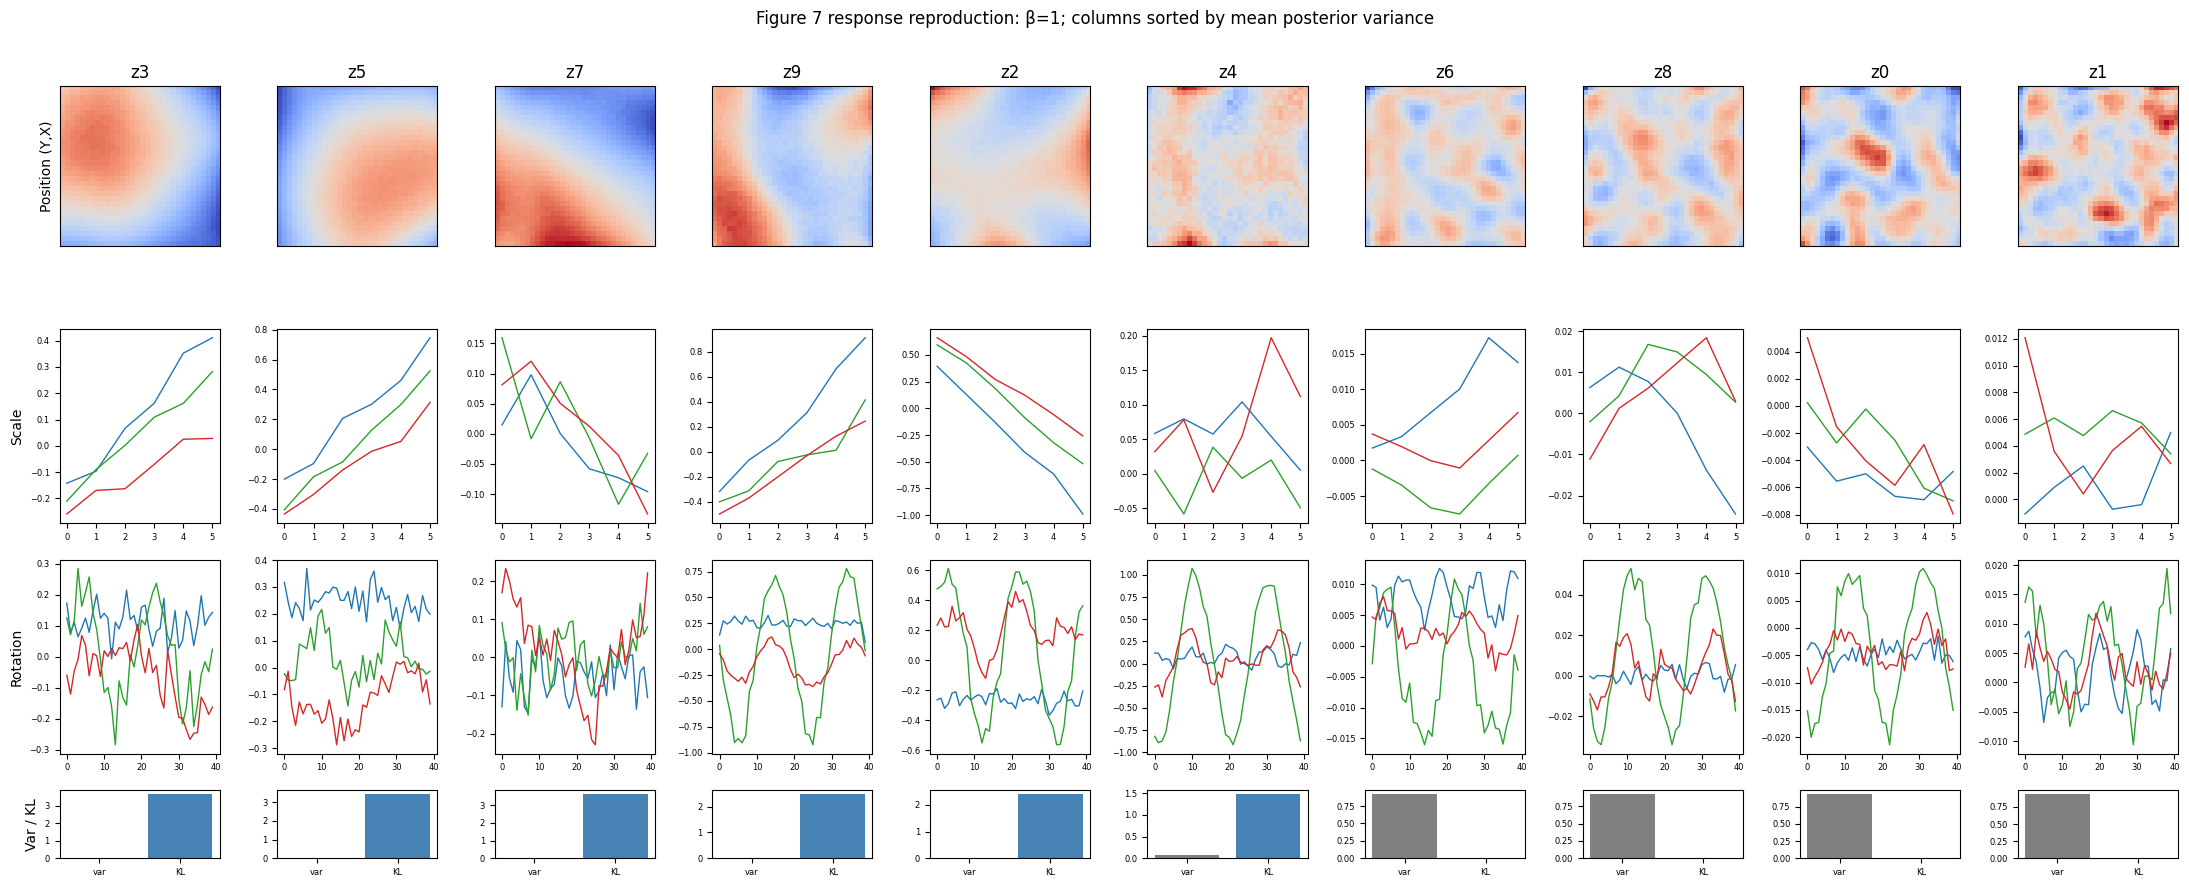

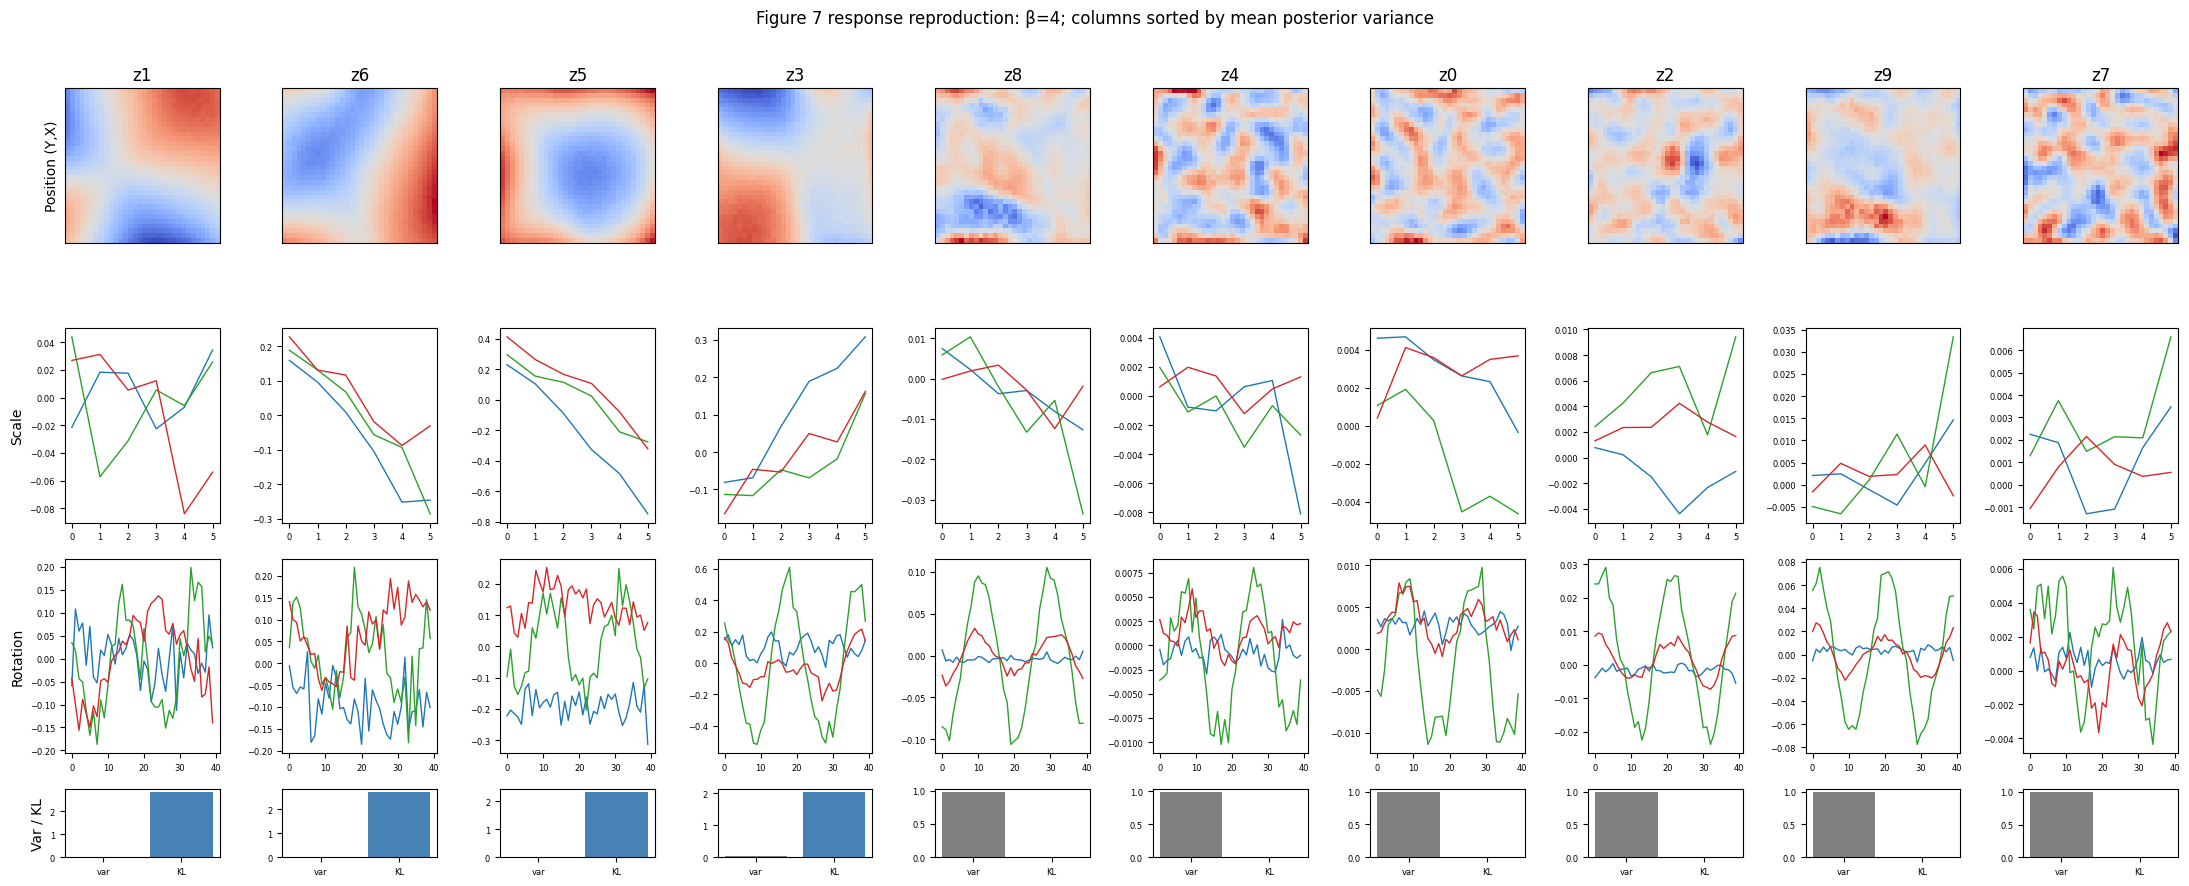

In [14]:
def plot_responses(beta,model):
    pos,scale,rotation,postvar,kl,order=responses(model)
    fig,axs=plt.subplots(4,10,figsize=(22,9),gridspec_kw={'height_ratios':[1.3,1,1,.35]})
    colors=['tab:blue','tab:green','tab:red'] # heart, oval, square (dSprites shape codes 1,2,3)
    for col,j in enumerate(order):
        axs[0,col].imshow(pos[:,:,j],cmap='coolwarm',origin='lower',vmin=-max(abs(pos[:,:,j].min()),abs(pos[:,:,j].max())),vmax=max(abs(pos[:,:,j].min()),abs(pos[:,:,j].max())))
        for shape in range(3):
            axs[1,col].plot(range(6),scale[shape,:,j],color=colors[shape],lw=1)
            axs[2,col].plot(range(40),rotation[shape,:,j],color=colors[shape],lw=1)
        axs[3,col].bar([0,1],[postvar[j],kl[j]],color=['gray','steelblue']);axs[3,col].set_xticks([0,1],['var','KL'],fontsize=7)
        axs[0,col].set_title(f'z{j}');axs[0,col].set_xticks([]);axs[0,col].set_yticks([])
        axs[1,col].tick_params(labelsize=6);axs[2,col].tick_params(labelsize=6);axs[3,col].tick_params(labelsize=6)
    for r,name in enumerate(['Position (Y,X)','Scale','Rotation','Var / KL']):axs[r,0].set_ylabel(name)
    fig.suptitle(f'Figure 7 response reproduction: β={beta}; columns sorted by mean posterior variance')
    fig.tight_layout();fig.savefig(OUT/f'figure7_beta{beta}_responses.png',dpi=180);plt.show()
    np.savez_compressed(OUT/f'beta{beta}_responses.npz',position=pos,scale=scale,rotation=rotation,posterior_variance=postvar,kl=kl,order=order)
    return order
orders={beta:plot_responses(beta,model) for beta,model in models.items()}


## Decoded traversals

The paper traverses each coordinate from −3 to +3, holding other coordinates at inferred values from an image. We show five distinct reference images (one row per image) for each of ten latent coordinates, in the variance-sorted order. The result is a larger, readable rendering of the lower panels of Figure 7.


Saved 10 traversal grids for β= 1
Saved 10 traversal grids for β= 4
Example traversal: 1


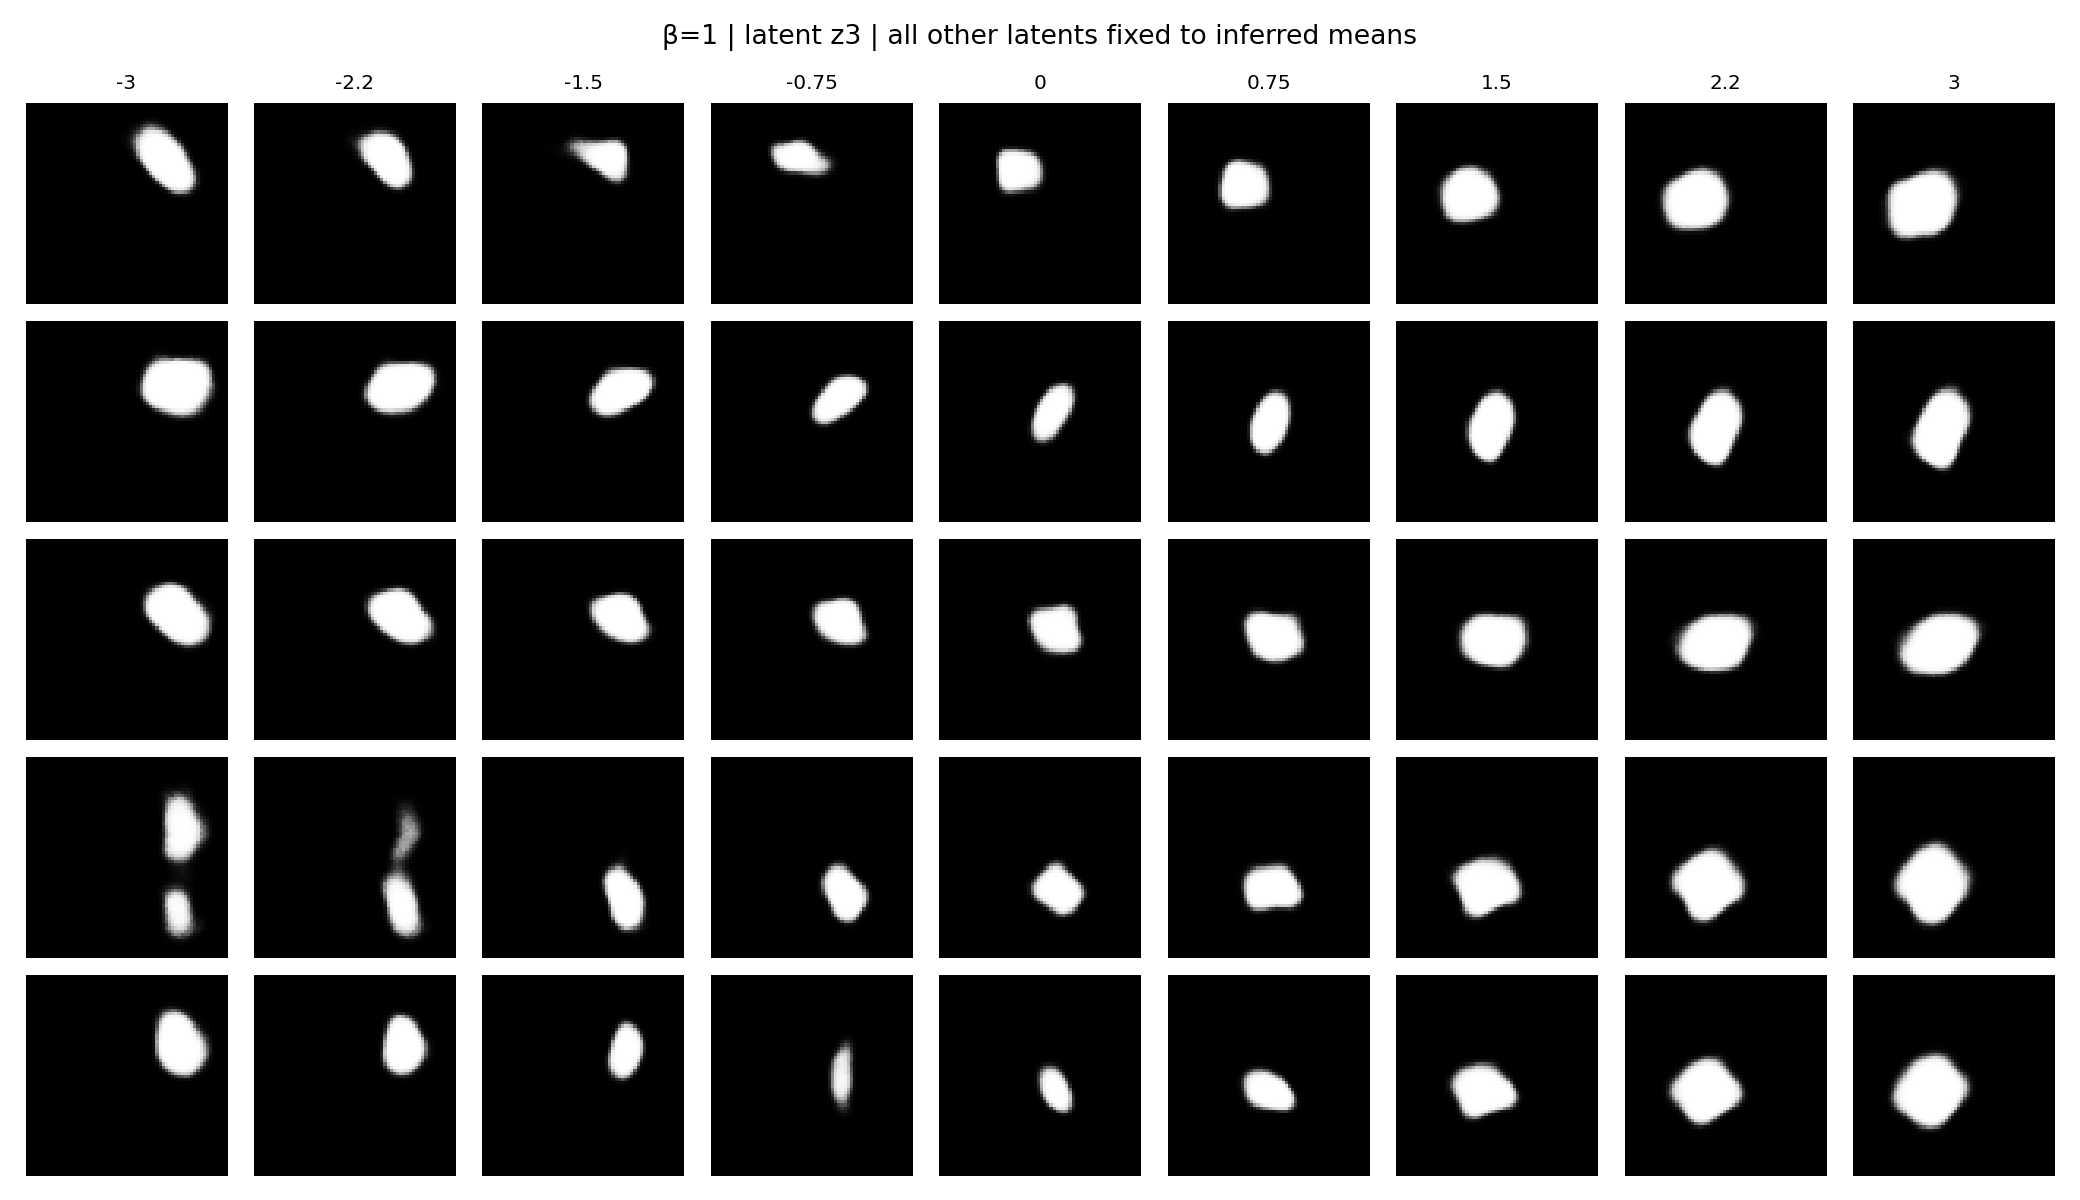

Example traversal: 4


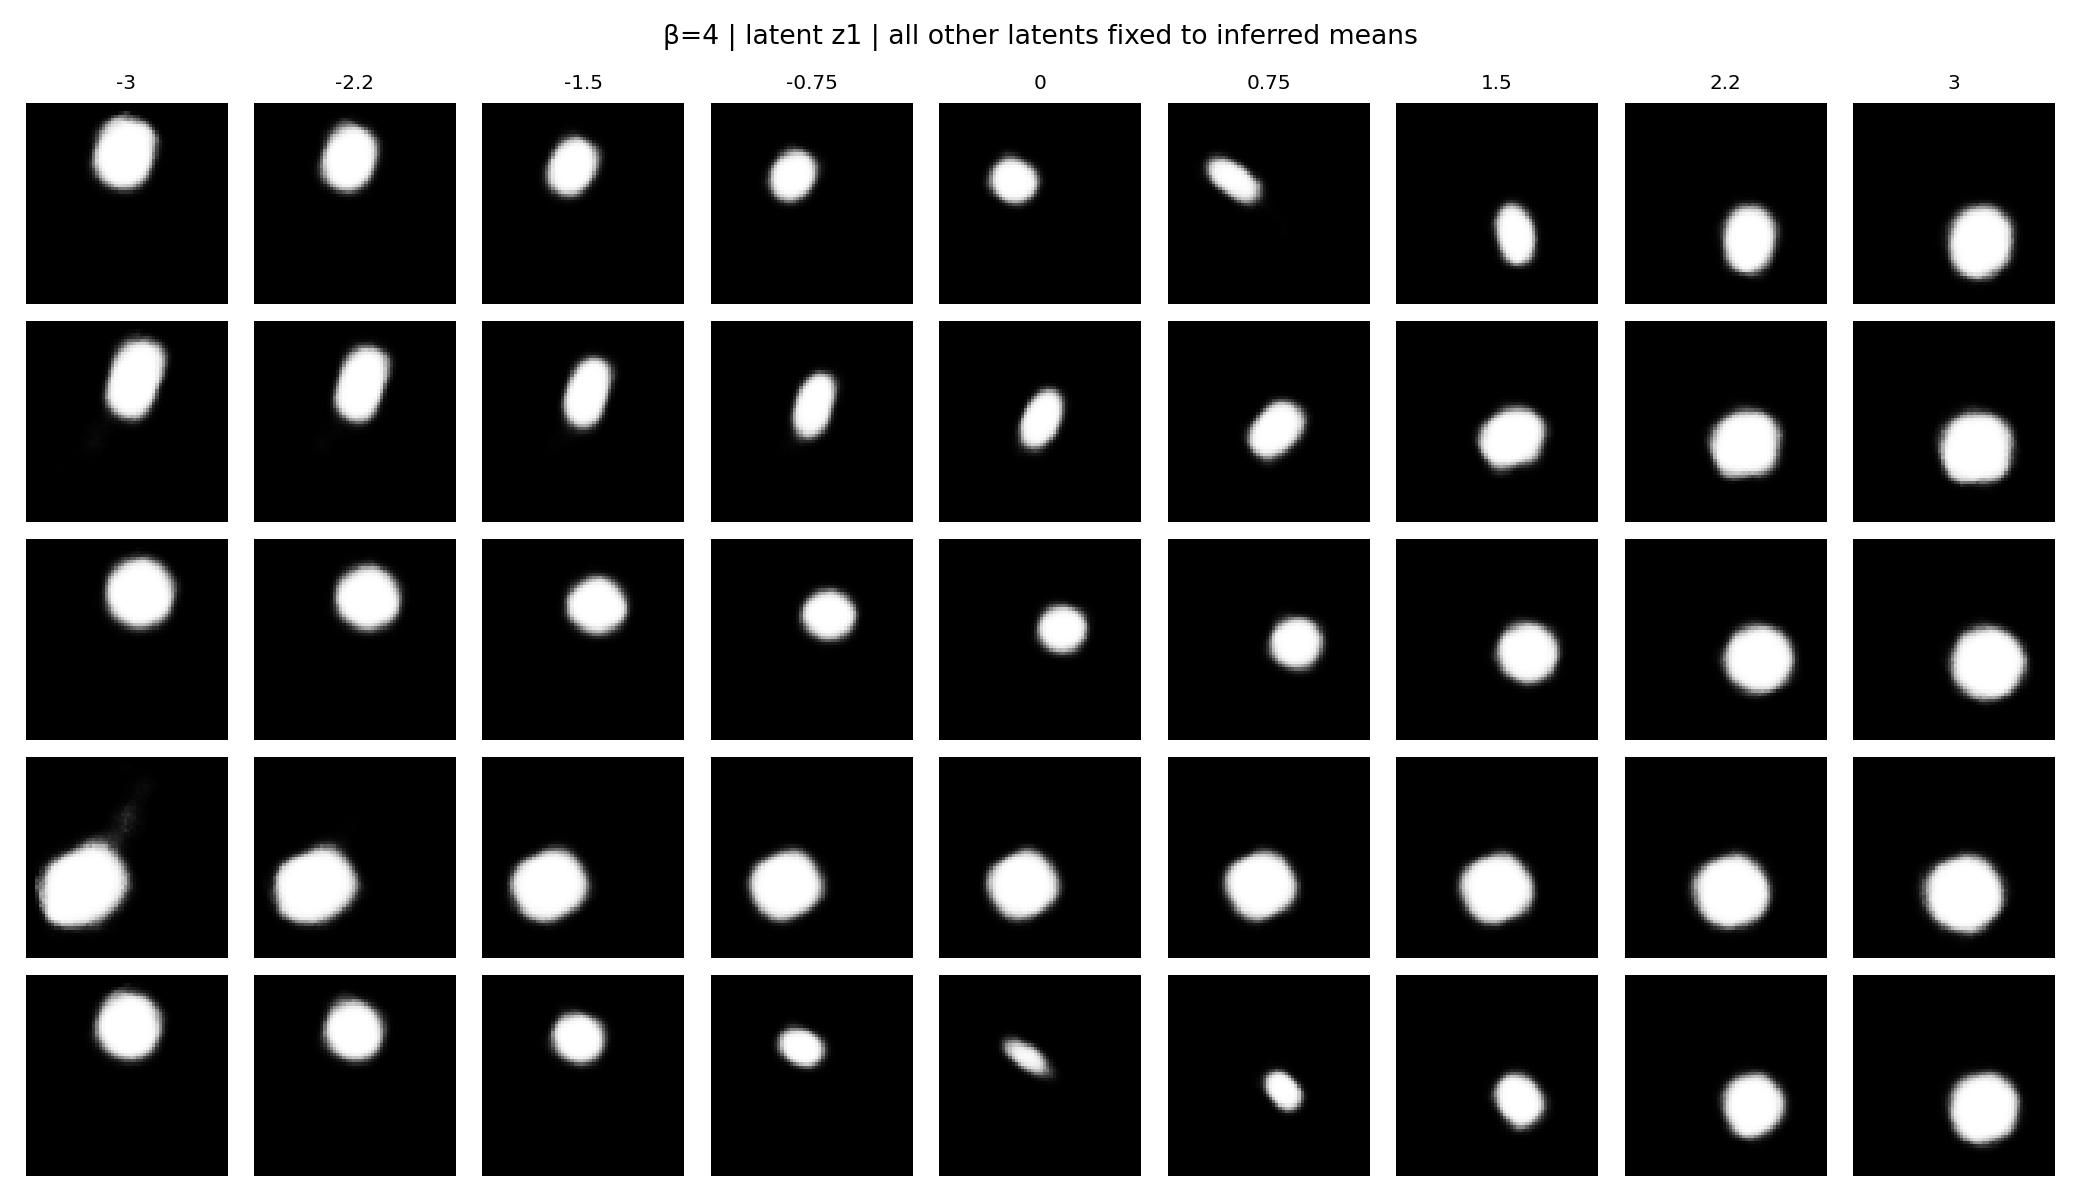

In [20]:
REFERENCE_FACTORS=np.array([[0,2,0,8,8],[1,3,8,16,16],[2,4,16,23,10],[0,5,24,10,24],[1,1,32,20,20]])
reference_idx=indices_from_factor_matrix(REFERENCE_FACTORS)
traversal=np.linspace(-3,3,9)
@torch.no_grad()
def plot_traversals(beta,model,order):
    model.eval();x=torch.from_numpy(np.asarray(imgs[reference_idx],dtype=np.float32).reshape(-1,4096)).to(DEVICE)
    mu,_=model.encode(x)
    for col,j in enumerate(order):
        zs=mu[:,None,:].repeat(1,len(traversal),1)
        zs[:,:,j]=torch.tensor(traversal,device=DEVICE,dtype=zs.dtype)
        images=torch.sigmoid(model.decode(zs.reshape(-1,10))).reshape(5,len(traversal),64,64).cpu().numpy()
        fig,axs=plt.subplots(5,len(traversal),figsize=(13,7.5))
        for r in range(5):
            for c,v in enumerate(traversal):
                axs[r,c].imshow(images[r,c],cmap='gray',vmin=0,vmax=1);axs[r,c].axis('off')
                if r==0:axs[r,c].set_title(f'{v:.2g}',fontsize=9)
        fig.suptitle(f'β={beta} | latent z{j} | all other latents fixed to inferred means')
        fig.tight_layout();fig.savefig(OUT/f'beta{beta}_traversal_z{j}.png',dpi=160);plt.close(fig)
    print('Saved 10 traversal grids for β=',beta)
for beta,model in models.items():plot_traversals(beta,model,orders[beta])
from IPython.display import display,Image
for beta in [1,4]:
    print('Example traversal:',beta)
    display(Image(filename=str(OUT/f'beta{beta}_traversal_z{orders[beta][0]}.png')))


## Saving and interpreting

All plots, numerical response arrays, epoch diagnostics and final checkpoints are in `OUT`. Zip them and download from Colab. Do **not** report the paper's factor-to-latent mapping as a reproduced result unless your own plots demonstrate it. Latent coordinates can permute or flip signs across training runs. Compare whether single coordinates respond selectively to position, scale and rotation, and whether traversal changes one factor at a time. Compare reconstruction loss versus KL to assess the β trade-off. For a stronger replication, run multiple independent seeds and increase training duration; the paper used ten seeds for its **quantitative** metric, but does not specify the exact Fig. 7 training duration.


In [18]:
import shutil
archive=shutil.make_archive(str(OUT),'zip',root_dir=OUT)
print('Saved:',archive)
if Path('/content').exists():
    from google.colab import files
    files.download(archive)


Saved: /content/beta_vae_fig7_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>